# CampusPath — A Simple Agentic LangGraph System

This notebook is designed for someone learning LangGraph for the first time. It is completely
separate from the FastAPI application and contains its own data loading, tools, state, nodes, graph,
checkpoint memory, and execution example.

The genuine problem: a student wants an AI-focused semester, but course interests alone are not
enough. The system must inspect the transcript, degree requirements, prerequisites, section capacity,
timetable constraints, and academic policy before giving a safe recommendation.

## 1. What makes this agentic?

A deterministic workflow would hard-code:

```text
always call transcript → always call prerequisites → always call sections
```

CampusPath does not hard-code the tool sequence. The model reads the objective and decides:

- which tools are needed;
- which arguments to send;
- whether several independent tools should be called together;
- whether enough evidence exists to answer.

The graph only provides a safe boundary and a maximum of two evidence-gathering rounds. Therefore,
the system is adaptive but still easy to observe in class.

## 2. The small graph we will build

```text
START
  ↓
make_plan
  ↓
agent ───────────────→ END (if the agent can answer)
  │
  │ tool calls
  ▼
tools
  │
  ├──→ agent (one more evidence round is allowed)
  │
  └──→ final_answer → END (after the second round)
```

`make_plan` and `agent` use the same model. This is one agent in two phases—not a multi-agent system.

## 3. Imports and notebook-only files

The notebook reads only `notebooks/demo_data` and writes only `notebooks/runtime`. It never imports
`app` and never uses the FastAPI database.

In [41]:
import json
import os
import re
from pathlib import Path
from pprint import pprint
from typing import Annotated
from uuid import uuid4

from dotenv import load_dotenv
from IPython.display import Image, Markdown, display
from langchain_core.messages import AIMessage, AnyMessage, HumanMessage, SystemMessage
from langchain_core.tools import tool
from langchain_openai import ChatOpenAI
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import END, START, StateGraph
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode
from pydantic import BaseModel, Field
from typing_extensions import TypedDict


def find_notebook_dir(start: Path) -> Path:
    candidates = [start, start / "notebooks", *[parent / "notebooks" for parent in start.parents]]
    for candidate in candidates:
        if (candidate / "demo_data" / "seed").is_dir():
            return candidate.resolve()
    raise FileNotFoundError("Could not find notebooks/demo_data/seed.")


NOTEBOOK_DIR = find_notebook_dir(Path.cwd().resolve())
DATA_DIR = NOTEBOOK_DIR / "demo_data"
RUNTIME_DIR = NOTEBOOK_DIR / "runtime"
RUNTIME_DIR.mkdir(parents=True, exist_ok=True)
load_dotenv(NOTEBOOK_DIR.parent / ".env")

print("Notebook directory:", NOTEBOOK_DIR)
print("Backend app imported: False")

Notebook directory: D:\Users data\Documents\Project_13_Agents\notebooks
Backend app imported: False


## 4. Load the standalone academic data

For a first LangGraph lesson, dictionaries are easier to inspect than a repository class. The
production API can still use SQLite; this notebook focuses on agent concepts.

`load_json(filename)` reads one file from the notebook's private seed directory and returns Python
lists and dictionaries.

In [42]:
SEED_DIR = DATA_DIR / "seed"
POLICY_DIR = DATA_DIR / "policies"


def load_json(filename: str):
    return json.loads((SEED_DIR / filename).read_text(encoding="utf-8"))


STUDENTS = {row["student_id"]: row for row in load_json("students.json")}
COURSES = {row["course_code"]: row for row in load_json("courses.json")}
PROGRAMS = {row["program_id"]: row for row in load_json("program_requirements.json")}
SECTIONS = {row["section_id"]: row for row in load_json("course_sections.json")}
MEMORIES = load_json("student_memories.json")
RECORD_GROUPS = load_json("academic_records.json")
ACADEMIC_RECORDS = {group["student_id"]: group["records"] for group in RECORD_GROUPS}

print("Students:", len(STUDENTS))
print("Courses:", len(COURSES))
print("Sections:", len(SECTIONS))

Students: 6
Courses: 21
Sections: 15


## 5. Define a small, useful toolset

We use six read-only tools. The `@tool` decorator turns a Python function and its type hints into a
model-visible name, description, and argument schema.

The tools return facts; the model decides how to combine them. This separation prevents the model from
inventing grades, prerequisites, or available seats.

In [43]:
@tool
def get_student_profile(student_id: str) -> dict:
    """Get the student's program, standing, goals, preferences, and constraints."""
    if student_id not in STUDENTS:
        raise ValueError(f"Student {student_id} was not found.")
    return STUDENTS[student_id]


@tool
def get_academic_history(student_id: str) -> list[dict]:
    """Get completed, failed, withdrawn, and pending academic records."""
    return ACADEMIC_RECORDS.get(student_id, [])


@tool
def check_prerequisites(student_id: str, course_code: str) -> dict:
    """Check a course's prerequisites against completed official records."""
    course = COURSES.get(course_code)
    if not course:
        raise ValueError(f"Course {course_code} was not found.")
    completed = {
        row["course_code"]
        for row in ACADEMIC_RECORDS.get(student_id, [])
        if row["status"] == "completed"
    }
    unmet = [item for item in course["prerequisites"] if item not in completed]
    return {
        "course_code": course_code,
        "required": course["prerequisites"],
        "unmet": unmet,
        "eligible": not unmet,
    }


@tool
def run_degree_audit(student_id: str) -> dict:
    """Find remaining degree categories and specialization gateway courses."""
    student = STUDENTS[student_id]
    program = PROGRAMS[student["program_id"]]
    completed = {
        row["course_code"]
        for row in ACADEMIC_RECORDS.get(student_id, [])
        if row["status"] == "completed"
    }
    requirements = []
    for requirement in program["requirements"]:
        missing = [code for code in requirement["required_courses"] if code not in completed]
        requirements.append({
            "category": requirement["category"],
            "minimum_credits": requirement["minimum_credits"],
            "missing_required_courses": missing,
        })
    specialization = next(
        (item for item in program["specializations"] if item["name"] == student["desired_specialization"]),
        None,
    )
    missing_gateways = [] if not specialization else [
        code for code in specialization["gateway_courses"] if code not in completed
    ]
    return {
        "program": program["program_name"],
        "earned_credits": student["earned_credits"],
        "total_required": program["total_credits"],
        "remaining_total": max(program["total_credits"] - student["earned_credits"], 0),
        "requirements": requirements,
        "desired_specialization": student["desired_specialization"],
        "missing_specialization_gateways": missing_gateways,
    }


@tool
def find_course_sections(course_code: str, term: str) -> list[dict]:
    """Find term sections with schedule, room, accessibility, and available seats."""
    results = []
    for section in SECTIONS.values():
        if section["course_code"] == course_code and section["term"] == term:
            results.append({
                **section,
                "available_seats": max(section["capacity"] - section["enrolled"] - section["reserved"], 0),
            })
    return results


@tool
def search_academic_policy(query: str, top_k: int = 3) -> list[dict]:
    """Search notebook policy documents and return the strongest evidence passages."""
    query_terms = set(re.findall(r"[a-z0-9]+", query.lower()))
    results = []
    for path in POLICY_DIR.glob("*.md"):
        text = path.read_text(encoding="utf-8")
        terms = set(re.findall(r"[a-z0-9]+", text.lower()))
        overlap = query_terms & terms
        if overlap:
            results.append({
                "source": path.name,
                "score": round(len(overlap) / max(len(query_terms), 1), 3),
                "matched_terms": sorted(overlap),
                "excerpt": text[:1200],
            })
    return sorted(results, key=lambda item: item["score"], reverse=True)[:top_k]


tools = [
    get_student_profile,
    get_academic_history,
    check_prerequisites,
    run_degree_audit,
    find_course_sections,
    search_academic_policy,
]
print([item.name for item in tools])

['get_student_profile', 'get_academic_history', 'check_prerequisites', 'run_degree_audit', 'find_course_sections', 'search_academic_policy']


## 6. Call tools directly before giving them to an agent

This step proves that tools are ordinary testable Python functions. The student is eligible for
Applied Data Analytics, but Machine Learning is blocked by missing Linear Algebra (`MA202`).

In [44]:
profile = get_student_profile.invoke({"student_id": "STU-2024-017"})
ml_status = check_prerequisites.invoke({"student_id": "STU-2024-017", "course_code": "CS301"})
analytics_status = check_prerequisites.invoke({"student_id": "STU-2024-017", "course_code": "DS301"})
pprint({"student": profile["full_name"], "machine_learning": ml_status, "data_analytics": analytics_status})

{'data_analytics': {'course_code': 'DS301',
                    'eligible': True,
                    'required': ['CS201', 'MA201'],
                    'unmet': []},
 'machine_learning': {'course_code': 'CS301',
                      'eligible': False,
                      'required': ['CS102', 'MA201', 'MA202'],
                      'unmet': ['MA202']},
 'student': 'Aanya Rao'}


## 7. Define the smallest useful LangGraph state

State is the shared dictionary passed between nodes.

- `messages` uses `add_messages`, so new model and tool messages are appended correctly.
- `student_id` and `term` identify the academic case.
- `plan` stores a short, visible plan.
- `agent_rounds` bounds the tool loop for a beginner-friendly demonstration.

In [45]:
class AgentState(TypedDict, total=False):
    messages: Annotated[list[AnyMessage], add_messages]
    student_id: str
    term: str
    plan: list[str]
    agent_rounds: int

## 8. Configure one model for planning and tool use

`with_structured_output(SimplePlan)` asks the model for a validated list of steps.
`bind_tools(tools)` gives the same model permission to choose from our six tools.

No graph is created when the key is missing, so all earlier learning cells remain runnable.

In [46]:
class SimplePlan(BaseModel):
    steps: list[str] = Field(min_length=2, max_length=5)


api_key = os.getenv("OPENAI_API_KEY", "")
model = None
planner_model = None
agent_model = None

if api_key:
    model = ChatOpenAI(
        model=os.getenv("OPENAI_MODEL", "gpt-5-mini"),
        api_key=api_key,
        temperature=1,
        timeout=60,
        max_retries=2,
    )
    planner_model = model.with_structured_output(SimplePlan)
    agent_model = model.bind_tools(tools)
    print("Model ready.")
else:
    print("Add OPENAI_API_KEY to .env to run the graph cells.")

Model ready.


## 9. Define four small nodes

- `make_plan`: creates two to five visible steps.
- `agent`: decides which tools to call or writes an answer.
- `tools`: LangGraph's built-in `ToolNode` executes calls and adds `ToolMessage` results.
- `final_answer`: produces a conclusion without allowing more tools after the bounded loop.

Tool selection remains dynamic; only the maximum number of rounds is fixed.

In [47]:
async def make_plan(state: AgentState) -> dict:
    objective = state["messages"][0].content
    result = await planner_model.ainvoke([
        SystemMessage(content="Create a short evidence-gathering plan. Do not answer the question yet."),
        HumanMessage(content=objective),
    ])
    return {"plan": result.steps, "agent_rounds": 0}


async def agent(state: AgentState) -> dict:
    system_prompt = (
        f"You are one adaptive academic planning agent.\n"
        f"Student: {state['student_id']}\n"
        f"Term: {state['term']}\n"
        f"Visible plan: {state['plan']}\n\n"
        "Choose the tools needed to verify the request. Call independent tools together when possible. "
        "Use at most two evidence-gathering rounds. Never invent grades, prerequisites, seats, or policy. "
        "If evidence is sufficient, answer with the recommended plan and clearly explain blocked courses."
    )
    response = await agent_model.ainvoke([SystemMessage(content=system_prompt), *state["messages"]])
    return {"messages": [response], "agent_rounds": state.get("agent_rounds", 0) + 1}


tool_node = ToolNode(tools)


async def final_answer(state: AgentState) -> dict:
    response = await model.ainvoke([
        SystemMessage(content=(
            "Write the final student-friendly recommendation using only the collected tool evidence. "
            "Include prerequisite issues, degree-path impact, section facts, and assumptions."
        )),
        *state["messages"],
    ])
    return {"messages": [response]}

## 10. Routing keeps the graph agentic but bounded

After `agent`, the latest model message decides the path:

- tool calls present → `tools`;
- no tool calls → `END`.

After tools, the graph allows another agent decision only when fewer than two rounds have occurred.
This prevents the long repetitive trace seen in the earlier notebook.

In [48]:
def route_after_agent(state: AgentState):
    last_message = state["messages"][-1]
    return "tools" if isinstance(last_message, AIMessage) and last_message.tool_calls else END


def route_after_tools(state: AgentState):
    return "agent" if state.get("agent_rounds", 0) < 2 else "final_answer"

## 11. Build the LangGraph

`StateGraph(AgentState)` defines the state contract. Nodes are Python callables. Normal edges always
follow one route; conditional edges call a routing function. `InMemorySaver` checkpoints state by
`thread_id` for the life of this notebook kernel.

In [49]:
graph = None
if model is not None:
    builder = StateGraph(AgentState)
    builder.add_node("make_plan", make_plan)
    builder.add_node("agent", agent)
    builder.add_node("tools", tool_node)
    builder.add_node("final_answer", final_answer)

    builder.add_edge(START, "make_plan")
    builder.add_edge("make_plan", "agent")
    builder.add_conditional_edges("agent", route_after_agent, {"tools": "tools", END: END})
    builder.add_conditional_edges("tools", route_after_tools, {"agent": "agent", "final_answer": "final_answer"})
    builder.add_edge("final_answer", END)

    graph = builder.compile(checkpointer=InMemorySaver())
    print("Graph compiled.")

Graph compiled.


## 12. Display LangGraph's own graph chart

`graph.get_graph()` asks the compiled LangGraph for its actual topology. We first request LangGraph's
Mermaid PNG. If that renderer is unavailable, the cell falls back to Mermaid text and then ASCII.

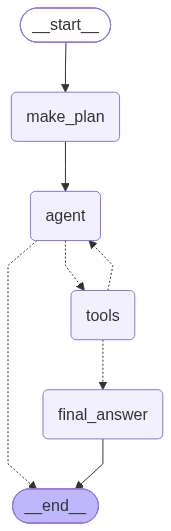

In [50]:
if graph is not None:
    try:
        display(Image(graph.get_graph().draw_mermaid_png()))
    except Exception as exc:
        print("PNG renderer unavailable:", exc)
        mermaid = graph.get_graph().draw_mermaid()
        display(Markdown(f"```mermaid\n{mermaid}\n```"))

## 13. Run it with simple, readable events

The previous notebook printed every changed state field. This version prints only what a beginner
needs: the plan, selected tool names, completion of tool execution, and the final answer.

`thread_id` identifies checkpoint memory. `recursion_limit=12` is a final guard in addition to the
two-round routing rule.

In [51]:
request = (
    "Build a 20 to 22 credit Semester 5 plan for STU-2024-017 that protects the Artificial "
    "Intelligence pathway, includes one humanities elective, avoids classes before 10:00 and "
    "Tuesday after 14:00, and explains why Machine Learning may or may not be eligible."
)
config = {
    "configurable": {"thread_id": f"class-demo-{uuid4()}"},
    "recursion_limit": 12,
}
initial_state = {
    "messages": [HumanMessage(content=request)],
    "student_id": "STU-2024-017",
    "term": "Monsoon 2026",
    "agent_rounds": 0,
}

if graph is not None:
    async for update in graph.astream(initial_state, config=config, stream_mode="updates"):
        node_name, change = next(iter(update.items()))
        if node_name == "make_plan":
            print("PLAN")
            for number, step in enumerate(change["plan"], start=1):
                print(f"  {number}. {step}")
        elif node_name == "agent":
            message = change["messages"][-1]
            if message.tool_calls:
                print("AGENT chose tools:", [call["name"] for call in message.tool_calls])
            else:
                print("AGENT produced the final response.")
        elif node_name == "tools":
            print("TOOLS returned evidence to the agent.")
        elif node_name == "final_answer":
            print("FINAL ANSWER created after the bounded tool loop.")
else:
    print("Graph execution skipped because OPENAI_API_KEY is not configured.")

PLAN
  1. Confirm STU-2024-017’s current transcript: completed courses, earned credits, grades, and current GPA (to verify prerequisites and any year/standing requirements).
  2. Retrieve the program handbook for the student’s degree and the Artificial Intelligence pathway rules (required courses, core vs. electives, allowed substitutions, credit totals, and any course sequencing constraints).
  3. Get the official Semester 5 course catalogue and timetable: course codes, titles, credit values, meeting days/times (including labs/tutorials), instructors, and modality (online/in-person).
  4. Identify which Semester 5 courses are designated for the AI pathway and which are general electives (including the humanities elective list and available humanities sections with times).
  5. Check prerequisites and co-requisites for key AI-pathway courses (especially Machine Learning): confirm whether the student has satisfied them or needs concurrent enrollment/waivers. Collect course descriptions 

## 14. Read the final answer from checkpointed state

`aget_state(config)` retrieves the latest state for the same thread. The final item in `messages` is
displayed without printing the entire internal trace.

In [53]:
if graph is not None:
    snapshot = await graph.aget_state(config)
    final_message = snapshot.values["messages"][-1]
    display(Markdown("## CampusPath recommendation"))
    display(Markdown(final_message.content))

## CampusPath recommendation

Recommendation (Semester 5 plan — 20 credits, protects the Artificial Intelligence pathway)

Planned courses (target 20 credits)
- MA202 — Linear Algebra for Computing (assumed 4 credits)  
  Why: MA202 is a required gateway for the Artificial Intelligence specialization (degree audit shows MA202 missing). Take this now so you can take CS301 in a later term and keep the AI pathway on schedule.

- CS203 — (Core Computer Science) (assumed 4 credits)  
  Why: One of the remaining core CS requirements listed on your degree audit. Keeps core progression steady.

- CS304 — (Core Computer Science) (assumed 4 credits)  
  Why: Another required core from the degree audit; helps satisfy the core-credit minimums shown.

- Humanities elective (HU—any approved humanities elective, assumed 3 credits)  
  Why: You requested one humanities elective this term. Humanities credits are part of the program minima; you have some HU credit already but a further elective this term meets your preference.

- CS390 — Laboratory requirement (assumed 2 credits)  
  Why: Lab-category credit is listed as missing on the audit (CS390). Including the lab this term starts satisfying lab requirements.

- Program elective (AI-related if available, assumed 3 credits)  
  Why: Keeps elective options flexible and allows you to start building AI-related elective credit while MA202 is completed.

Total assumed credits: 4 + 4 + 4 + 3 + 2 + 3 = 20 credits (within the 20–22 requested range and above the scholarship minimum of 18 credits).

Prerequisite issues and Machine Learning (CS301) eligibility
- The degree audit and specialization policy identify MA202 and CS301 as gateway courses for the Artificial Intelligence specialization. Your profile shows MA202 is not yet completed.  
- The institutional prerequisite policy states a prerequisite is satisfied only when the official record shows a passing completed result (a course-in-progress does not satisfy the prerequisite), and concurrent registration is not allowed unless the catalog explicitly permits it. The collected evidence does not show an explicit allowance for taking CS301 concurrently with MA202.  
- Therefore, CS301 (Machine Learning Foundations) is likely NOT eligible for you this term unless one of the following occurs:
  - You have an approved prerequisite waiver or equivalency from the CS department (the waiver must be requested and approved by the course-owning department), or
  - The catalog explicitly allows concurrent enrollment (no evidence of that was found).
- Practical consequence: take MA202 now (this term). Register for CS301 in the next term after MA202 posts as completed to preserve the AI pathway. If you strongly prefer to attempt CS301 this term, contact the CS department immediately to request a prerequisite waiver and supply evidence of equivalent preparation (the policy explains the waiver process and documentation needs).

Degree-path impact
- Taking MA202 this term enables CS301 next term, which is required to keep your Artificial Intelligence specialization on track. The degree audit shows MA202 and CS301 are the missing AI gateways — delaying MA202 delays CS301 and therefore delays clearing the AI gateway requirement.  
- This semester plan prioritizes gateway (MA202), core requirements (CS203, CS304), the missing lab (CS390), and a humanities elective, while also giving space to accumulate relevant program-elective credits (AI-related if possible). That balances progression toward degree and specialization while meeting your scheduling and scholarship constraints.

Section facts and scheduling constraints (what I used and what you must check)
- Your recorded preferences: earliest class start 10:00; no classes Tuesday after 14:00. These are included as hard scheduling constraints in the plan.  
- The registration system is authoritative for actual section times, seat availability, and prerequisite enforcement; it will validate prerequisites, detect timetable conflicts, and check seat limits at enrollment time. Timetable conflicts are defined as any overlap in scheduled meetings.  
- I do not have specific section times or section IDs from the course catalog in the collected evidence. You must choose sections that start at or after 10:00 and do not schedule any meeting on Tuesday after 14:00. If a required course only offers sections that violate your constraints, you will need an advisor review or to request an alternative section if available.

Assumptions (explicit)
- Credit values per course are assumed from observed patterns in your academic history (most core courses have been 4 credits, humanities 3, small labs 2). The plan totals 20 credits under those assumptions. Actual credits should be verified at registration.  
- Specific section times and availability were not provided in the collected evidence. The plan assumes that sections exist for each course that meet your time constraints (start ≥ 10:00 and no Tue after 14:00). The registration service will confirm or reject that assumption.  
- CS301 is identified in the collected policy evidence as the Machine Learning gateway course; the plan assumes its prerequisite is MA202 and that concurrency is not permitted unless a waiver or explicit catalog permission exists (per the prerequisite policy excerpt).

Next steps (actionable)
1. Attempt to register for the listed courses, prioritizing MA202 first. During registration, pick sections that start at or after 10:00 and avoid Tuesday after 14:00.  
2. If CS301 appears in the registration portal as blocked by a prerequisite, do NOT assume you can enroll; instead, request a prerequisite waiver from the CS department if you have compelling evidence of equivalent preparation. The waiver must be approved by the department.  
3. If any required course has no section that fits your time constraints, contact your academic advisor (ADV-CS-02) promptly to request alternatives or an advisor-mediated section assignment. The registration system will be the final authority on seat reservations and conflicts.  
4. Confirm total credits and scholarship implications at checkout — you must register at least 18 credits to meet your scholarship condition; this plan (as assumed) reaches 20 credits, which satisfies that requirement.

If you want, I can:
- Draft a short waiver request template you could submit to the CS department (if you want to attempt CS301 now), or
- Query available sections for the courses above and filter by your time constraints (I will need access to the current term section data to do that).

## 15. What to remember

- The graph is small, but the agent is still adaptive because the model selects tools and arguments.
- State carries messages, the visible plan, the student, the term, and the bounded round count.
- `ToolNode` executes tool calls; conditional edges decide whether to use tools or finish.
- Checkpoint memory is addressed by `thread_id`.
- The two-round limit keeps the classroom trace understandable.
- The FastAPI application can retain the more defensive production graph; this notebook is the
  beginner-friendly learning version.